# 01 — Model-Based 4DVar on Lorenz-63

Classical strong-constraint 4DVar with the *true* Lorenz-63 dynamics as the
model. This is the reference point for every later notebook: the learned
methods replace pieces of this picture, and their value is measured
against it.

## The problem

We are given a background estimate $x_b$ of the state at the start of an
assimilation window, and noisy, gappy observations $y_t$ along it. The
model $M$ is treated as *perfect*: the state at any later time is
$x_t = M_t(x_0)$, so the whole trajectory is determined by the initial
state and the only unknown is $x_0$. The generative model is

$$
x_0 \sim \mathcal{N}(x_b, B), \qquad
y_t = m_t \odot \big(H\, M_t(x_0) + \varepsilon_t\big), \quad
\varepsilon_t \sim \mathcal{N}(0, R),
$$

and the analysis is the maximum a posteriori estimate of $x_0$,

$$
x_0^* = \underset{x_0}{\arg\min}\; J(x_0), \qquad
J(x_0) = \tfrac{1}{2}\|x_0 - x_b\|^2_{B^{-1}}
  + \tfrac{1}{2}\sum_{t=0}^{T} \|m_t \odot (y_t - H\, M_t(x_0))\|^2_{R^{-1}} ,
$$

where $\|v\|^2_{A} = v^\top A v$. The "strong constraint" is the perfect
model assumption: the dynamics are imposed exactly, not penalised, and
the observations can only choose *which* model trajectory, never bend it.
Chapter [6](../06_strong_4dvar.md) derives this cost; chapter
[7](../07_weak_4dvar.md) relaxes the constraint by adding model-error
increments to the control vector.

## The geometry

Think of the set of all model trajectories over the window as a
3-dimensional surface embedded in the $(T+1) \times 3$-dimensional space of
state sequences, parameterised by $x_0$. The observations are a point in
that space (with missing coordinates), and 4DVar finds the point on the
surface closest to them in the $R^{-1}$ metric, pulled toward the
background in the $B^{-1}$ metric. With a linear model and linear $H$ this
is a least-squares projection and the answer is closed-form (the BLUE of
chapter [4](../04_oi_blue.md)); with Lorenz-63 the surface is curved and
we need an iterative minimiser.

## The gradient

The minimiser needs $\nabla J$, and the chain rule through the rollout gives

$$
\nabla_{x_0} J = B^{-1}(x_0 - x_b)
  + \sum_{t=0}^{T} \big(M_t'\big)^{\!\top} H^\top D_t\, R^{-1} D_t \big(H M_t(x_0) - y_t\big),
\qquad D_t = \mathrm{diag}(m_t),
$$

where the mask appears on both sides of $R^{-1}$ (the cost is the
$R^{-1}$-norm of the *masked* residual, so unobserved coordinates receive
no gradient even when $R$ is non-diagonal), $M_t' = \partial M_t / \partial x_0$
is the tangent-linear model and
its transpose is the *adjoint* model. Classical DA systems hand-code the
adjoint; here `jax.grad` derives it from the forward model, and the
`diffrax` adjoint strategy decides how much of the forward trajectory to
store versus recompute (chapter [12](../12_adjoint_methods.md)). The
outer minimiser is BFGS, a quasi-Newton method that builds up curvature
information from successive gradients; operational systems use the
incremental (Gauss–Newton) scheme of chapter
[8](../08_incremental_4dvar.md), which linearises $M_t$ once per outer
loop and solves a quadratic inner problem.

## Where the pieces live

All of this is [`StrongFourDVar`](xref:api#vardax.StrongFourDVar). The forward model
$M_t$ comes from a [`DynTrajectory`](xref:api#vardax.DynTrajectory) ODE prior via
`as_forward_model`, so the same object that serves as a dynamical prior
elsewhere drives the rollout here; $B$ and $R$ are `lineax` operators, so
correlated errors are a one-line change.

In [1]:
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt

from vardax import (
    Batch1D,
    DynTrajectory,
    Lorenz63,
    MaskedIdentity,
    StrongFourDVar,
    simulate_lorenz63,
)

## 1. Truth, background, and observations

We simulate Lorenz-63 on the attractor, take one assimilation window of
$T + 1$ states at spacing $\Delta t = 0.05$, and observe every other step
with Gaussian noise. The background $x_b$ is the true initial state
perturbed with a larger error than the observations carry.

The window is one time unit long — about one Lyapunov time for Lorenz-63
($\lambda_1 \approx 0.9$), so errors in $x_0$ grow by a factor $e$ across
it. That is the sweet spot for strong-constraint 4DVar: long enough that
later observations constrain $x_0$ through the dynamics, short enough that
$J$ is still smooth and unimodal. Chapter [6](../06_strong_4dvar.md)
describes what happens when the window grows past this.

In [2]:
DT_SIM, SUBSAMPLE = 0.01, 5
DT = DT_SIM * SUBSAMPLE  # observation / model step
T = 20  # rollout steps; the window holds T + 1 states
SIGMA_OBS, SIGMA_BG = 0.5, 2.0

key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(key, dt=DT_SIM, n_steps=2000, n_burn_in=1000)
start = 500
x_true = states[start : start + SUBSAMPLE * (T + 1) : SUBSAMPLE]  # (T+1, 3)
ts = jnp.arange(T + 1) * DT

k_obs, k_bg = jax.random.split(jax.random.PRNGKey(1))
mask = jnp.zeros((T + 1, 3)).at[::2, :].set(1.0)
y_obs = x_true + SIGMA_OBS * jax.random.normal(k_obs, x_true.shape)
x_b = x_true[0] + SIGMA_BG * jax.random.normal(k_bg, (3,))

# StrongFourDVar consumes a Batch1D of shape (B, T+1, N); one window here.
batch = Batch1D(input=(y_obs * mask)[None], mask=mask[None], target=x_true[None])
print(f"window: {T + 1} states at dt={DT}, observed fraction {float(mask.mean()):.2f}")
print(f"background error |x_b - x_0|: {float(jnp.linalg.norm(x_b - x_true[0])):.3f}")

window: 21 states at dt=0.05, observed fraction 0.52
background error |x_b - x_0|: 1.621


## 2. The model and the analysis step

`Lorenz63` is the vector field; wrapping it in `DynTrajectory` gives an
ODE solve (Tsit5 with adaptive steps by default), and `as_forward_model`
exposes the one-step `step(state, dt)` interface `StrongFourDVar` rolls
out. $B = \sigma_b^2 I$ and $R = \sigma_{obs}^2 I$ use the true error
variances; the tag tells lineax they are positive definite so the cost can
apply $B^{-1}$ and $R^{-1}$ with conjugate gradients rather than forming
inverses.

With diagonal covariances the cost reduces to the weighted least squares
of the introduction with weights $1/2\sigma_b^2$ and $1/2\sigma_{obs}^2$:
here $\sigma_b / \sigma_{obs} = 4$, so a single observation is worth
sixteen background constraints and the analysis should move a long way
from $x_b$.

In [3]:
prior = DynTrajectory(model=Lorenz63(sigma=10.0, rho=28.0, beta=8.0 / 3.0))
forward = prior.as_forward_model(dt=DT)


def diag_cov(variance: float) -> lx.AbstractLinearOperator:
    op = lx.DiagonalLinearOperator(jnp.full(3, variance))
    return lx.TaggedLinearOperator(op, lx.positive_semidefinite_tag)


model = StrongFourDVar(
    forward=forward,
    obs_op=MaskedIdentity(),
    prior_mean=x_b,
    prior_cov_op=diag_cov(SIGMA_BG**2),
    obs_cov_op=diag_cov(SIGMA_OBS**2),
    max_steps=200,
)

x0_analysis = model(batch)[0]
print(f"analysis error   |x_0* - x_0|: {float(jnp.linalg.norm(x0_analysis - x_true[0])):.3f}")

analysis error   |x_0* - x_0|: 0.406


## 3. First guess vs analysis along the window

Rolling the background and the analysis through the same dynamics shows
what the observations bought. The first guess drifts away from the truth
at the Lyapunov rate; the analysed trajectory tracks it across the whole
window, including the unobserved steps and the unobserved half of the
time grid — the dynamics carry information from observed times to
unobserved ones, which is the whole point of assimilating a *window*
rather than a single snapshot (chapter [5](../05_threedvar.md)).

trajectory RMSE: first guess=1.126, analysis=0.111
observation RMSE (at observed points): 0.435


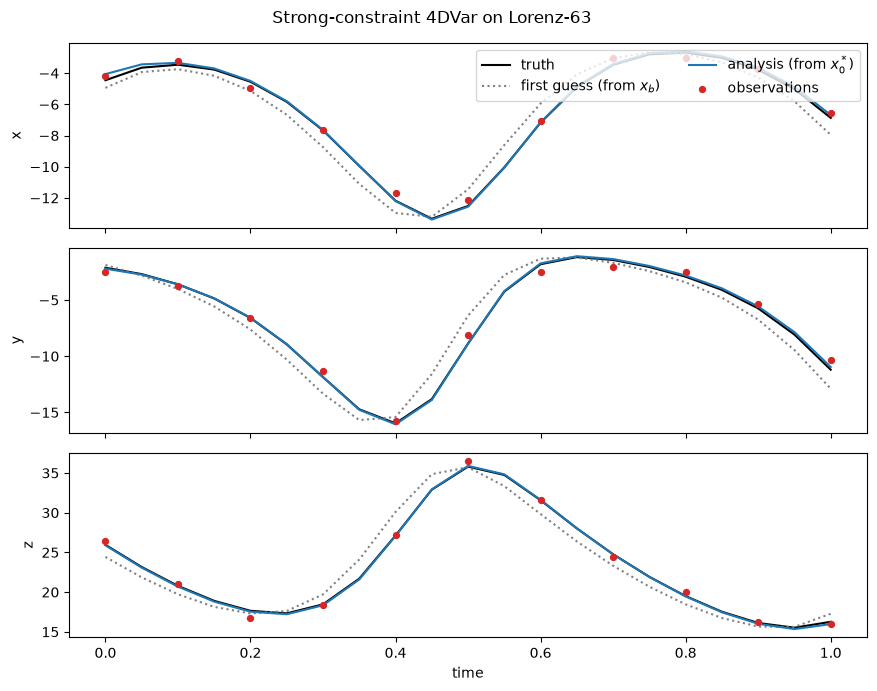

In [4]:
traj_first_guess = prior(x_b, ts)
traj_analysis = prior(x0_analysis, ts)

rmse = lambda traj: float(jnp.sqrt(jnp.mean((traj - x_true) ** 2)))  # noqa: E731
obs_rmse = float(jnp.sqrt(jnp.sum((mask * (y_obs - x_true)) ** 2) / mask.sum()))
print(f"trajectory RMSE: first guess={rmse(traj_first_guess):.3f}, analysis={rmse(traj_analysis):.3f}")
print(f"observation RMSE (at observed points): {obs_rmse:.3f}")

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(ts, x_true[:, i], color="black", label="truth")
    ax.plot(ts, traj_first_guess[:, i], color="gray", linestyle=":", label="first guess (from $x_b$)")
    ax.plot(ts, traj_analysis[:, i], color="tab:blue", label="analysis (from $x_0^*$)")
    ax.scatter(
        ts,
        jnp.where(mask[:, i] > 0, y_obs[:, i], jnp.nan),
        color="tab:red",
        s=18,
        zorder=5,
        label="observations",
    )
    ax.set_ylabel(name)
axes[0].legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("time")
fig.suptitle("Strong-constraint 4DVar on Lorenz-63")
plt.tight_layout()
plt.show()

## 4. Error budget

Two numbers summarise the analysis: the error in the control variable
$x_0$, and the error of the trajectory it generates over the window. The
second is what a forecast user sees. Note the trajectory RMSE of the
analysis is *below* the observation noise: the analysis is not an
interpolation of the observations but a model trajectory fitted to all of
them at once, so the noise averages out across the window.

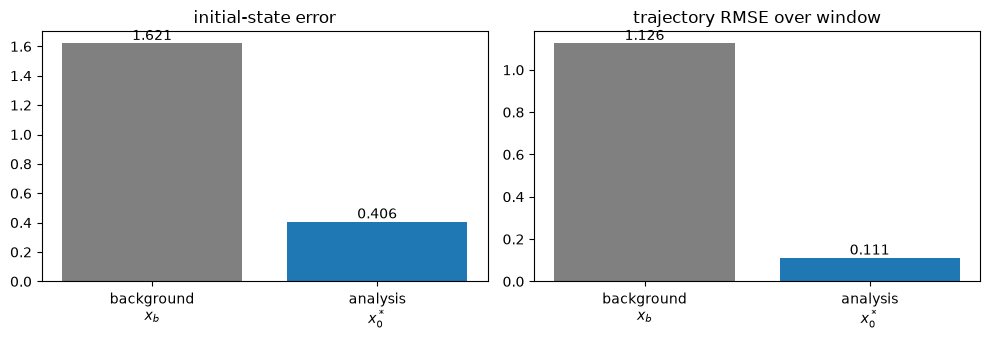

In [5]:
labels = ["background\n$x_b$", "analysis\n$x_0^*$"]
errors = [
    float(jnp.linalg.norm(x_b - x_true[0])),
    float(jnp.linalg.norm(x0_analysis - x_true[0])),
]
traj_errors = [rmse(traj_first_guess), rmse(traj_analysis)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, vals, title in zip(
    axes, [errors, traj_errors], ["initial-state error", "trajectory RMSE over window"]
):
    bars = ax.bar(labels, vals, color=["gray", "tab:blue"])
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:.3f}", ha="center", va="bottom")
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Summary

- Strong-constraint 4DVar is the MAP estimate of the initial state under
  a perfect-model assumption; the analysis is a model trajectory chosen
  to fit the background and all observations in the window.
- `StrongFourDVar` minimises that cost over $x_0$ with `optimistix` (BFGS
  by default); the gradient through the rollout is the adjoint model,
  derived by `jax.grad` rather than hand-coded.
- Any object with `step(state, dt)` can be the model. Here it is the
  Lorenz-63 ODE via `DynTrajectory.as_forward_model`; chapter
  [19](../19_physical_models.md) covers the ODE priors and notebook
  [09](09_param_estimation_L63.ipynb) makes their parameters learnable.
- Notebook [08](08_classical_4dvar_vs_4dvarnet_L63.ipynb) contrasts this
  model-based analysis with the learned 4DVarNet solver, and notebook
  [10](10_bilevel_opt_L63.ipynb) learns the cost weights that were set from
  known variances here.